### Основные выводы

Основные выводы:

1) Выбросы:
Для таргета есть явные выбросы, особенно в период между июль 2024 - май 2025. Кроме того, нет явного тренда, при этом стандартное отклонение меняется (возможно это повлияет на модель)
Общие характеристики по выбросам и отрицательным значениям:
- 99% перцентиль:, 377.79
- Количество значений выше P99:, 1052
- Доля значений выше P99: 1.00%
- Количество отрицательных значений: 4077
- Доля отрицательных значений: 3.88%

Возможно отрицательные значения не являются выбросами (специфика рынка). Нужно понять, являются ли выбросами значения выше 99 перцентиля.

Среди признаков наибольшее кол-во возможных выбросов (для дополнительной проверки) у wind forecast, solar forecast и net_exchange_forecast
выбросы выше 99% для wind_forecast_mwh:
 Доля значений выше P99: 1.00%
выбросы выше 99% для solar_forecast_mwh:
 Доля значений выше P99: 1.00%
выбросы выше 99% для net_exchange_forecast_mwh:
 Доля значений выше P99: 0.57%
выбросы выше 99% для demand_forecast_mwh:
 Доля значений выше P99: 1.00%

2) Есть явная сезонность для таргета: в течение дня, в течение недели и в течение года. Для некоторых из признаков также есть явная сезонность, например, сезонность для demand forecast во многом похожа на поведение таргета. При этом для nuclear_forecast в течение дня и недели сезонности нет (как и в целом динамики в среднем, значение внутри дня и внутри недели: 1900 и не меняется, при этом, возможно, есть сезонность (или скорее переключение режимов) в рамках года.
По графикам не видно явного тренда роста таргета из года в год, при этом, например, есть рост по уровню demand forecast

3) Признак с наибольшей положительной корреляцией с таргетом: demand forecast (pearson: 0.48). При этом есть заметная отрицательная корреляция с solar forecast и net_exhange forecast (-0.31 и -0.34 соответсвенно). При этом оба эти признака существенно скоррелированы друг с другом (0.71)

4) По корреляциям таргета с лаговым переменными:
-лаг на 1-7 дней: наибольшее значение 0.670075 с лагом на сутки для QH WAP
-лаг от 15 мин до 3 часов: наибольшее значение 0.743661 с лагом 4 (то есть час) для QH WAP

5) Наиболее высокая корреляция таргета в принципе - это корреляция со скользящей средней по таргету (4 прошлых значения таргета): 0.785043

Это наводит на мысль, что в качестве baseline модели стоит использовать автокорреляционную модель

### Загрузка и обработка

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import acf
from sklearn.preprocessing import StandardScaler

#для таблиц
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('hu_intraday_vwap_15min_2023_2025.csv')

In [3]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

df['timestamp'] = df['timestamp'].dt.tz_convert('Europe/Budapest')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105216 entries, 0 to 105215
Data columns (total 8 columns):
 #   Column                     Non-Null Count   Dtype                          
---  ------                     --------------   -----                          
 0   timestamp                  105216 non-null  datetime64[ns, Europe/Budapest]
 1   QH WAP                     105122 non-null  float64                        
 2   demand_forecast_mwh        105216 non-null  float64                        
 3   wind_forecast_mwh          105216 non-null  float64                        
 4   solar_forecast_mwh         105216 non-null  float64                        
 5   nuclear_forecast_mwh       105216 non-null  float64                        
 6   temperature_forecast_c     105216 non-null  float64                        
 7   net_exchange_forecast_mwh  105216 non-null  float64                        
dtypes: datetime64[ns, Europe/Budapest](1), float64(7)
memory usage: 6.4 MB


In [5]:
missing = df.isna().sum()

pd.DataFrame({
    'пропусков': missing,
    'доля, %': (missing / len(df) * 100).round(1),
})[missing > 0]

,пропусков,"доля, %"
QH WAP,94,0.1


In [6]:
df = df.dropna(subset=['QH WAP'])

In [7]:
df.describe().round(2)

,QH WAP,demand_forecast_mwh,wind_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c,net_exchange_forecast_mwh
count,105122.00,105122.00,105122.00,105122.00,105122.00,105122.00,105122.00
mean,107.53,4892.75,67.75,614.68,1731.60,12.54,-1130.71
std,82.04,827.14,62.94,905.32,236.16,9.21,1228.21
min,-561.85,2332.80,0.40,0.00,956.00,-7.35,-5365.30
25%,69.43,4263.20,17.50,0.00,1428.00,4.86,-1989.10
50%,99.44,4828.40,48.10,16.80,1900.00,12.14,-1300.00
75%,135.34,5453.68,99.00,1047.60,1900.00,19.76,-435.70
max,6326.67,7376.40,300.40,4207.60,2039.00,36.01,3819.90


### Описание QH WAP

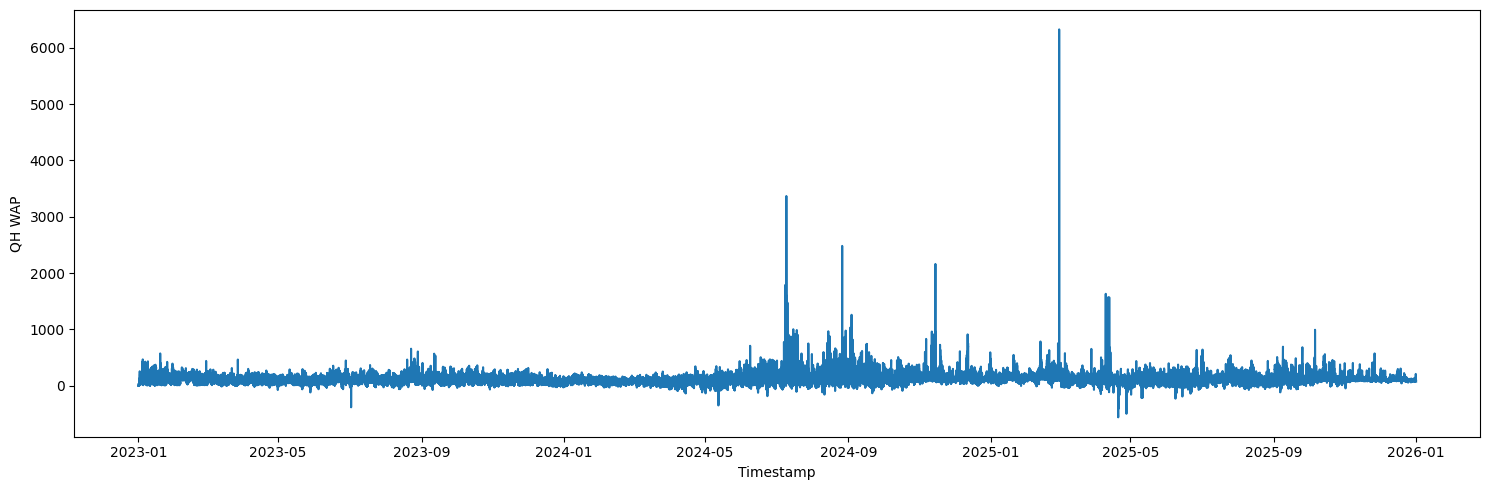

In [8]:
fig, ax = plt.subplots(figsize=(15, 5))

sns.lineplot(data=df, x='timestamp', y='QH WAP', ax=ax)

ax.set_xlabel('Timestamp')
ax.set_ylabel('QH WAP')

plt.tight_layout()
plt.show()

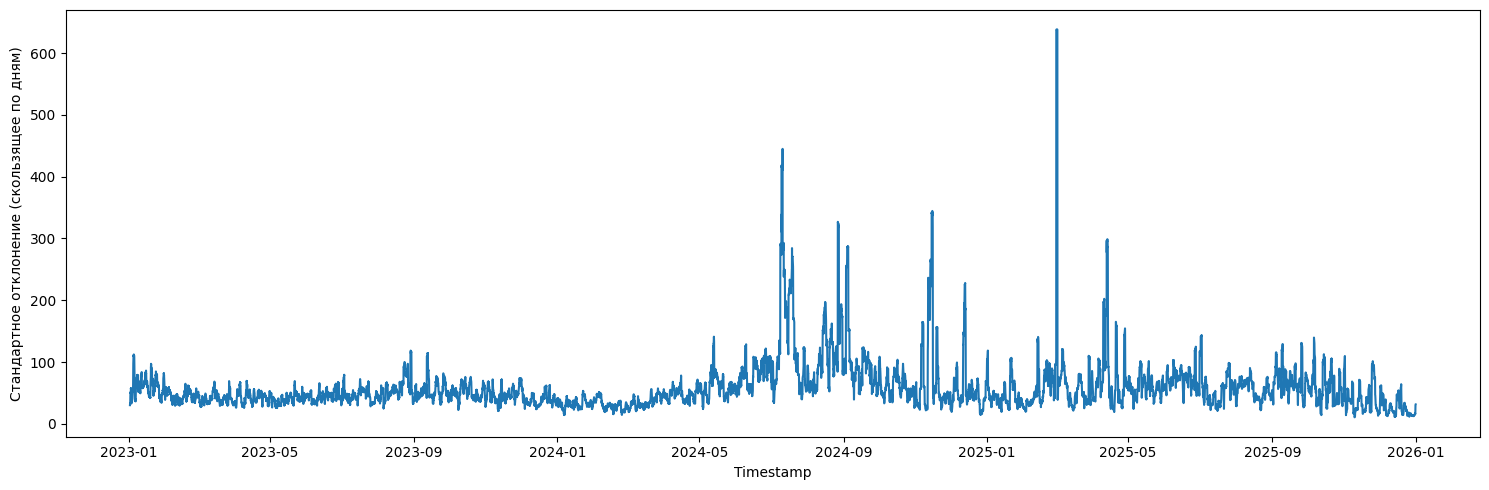

In [9]:
fig, ax = plt.subplots(figsize=(15, 5))

sns.lineplot(x=df['timestamp'], y=df['QH WAP'].rolling(window=96).std(), ax=ax)

ax.set_xlabel('Timestamp')
ax.set_ylabel('Стандартное отклонение (скользящее по дням)')

plt.tight_layout()
plt.show()

<Axes: >

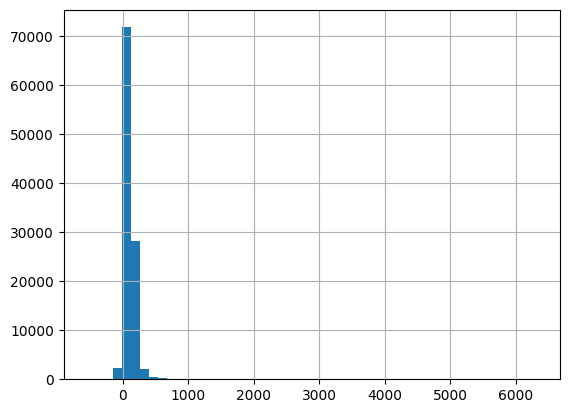

In [10]:
df['QH WAP'].hist(bins=50)

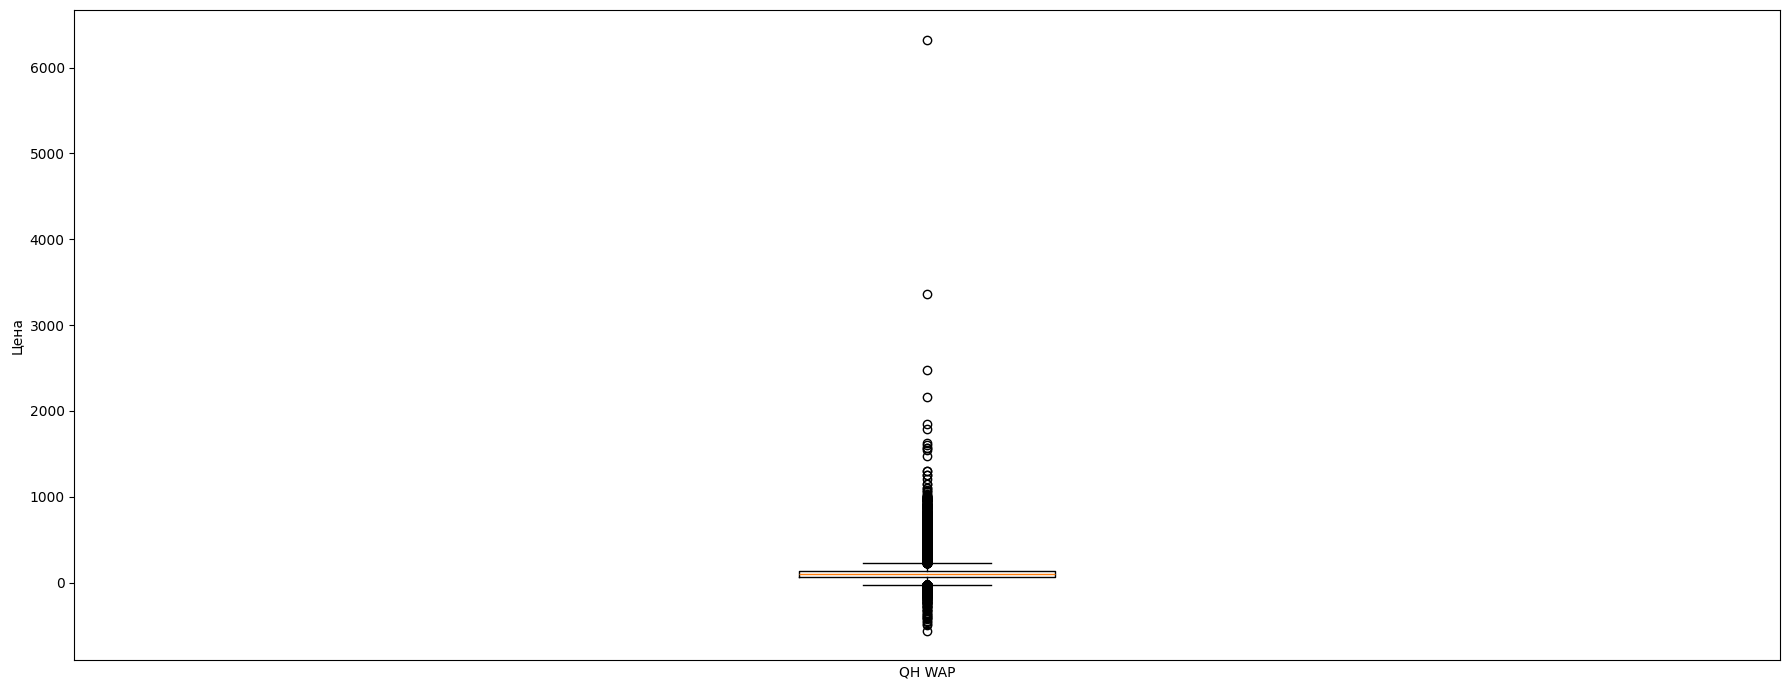

In [11]:
fig, ax = plt.subplots(figsize=(18, 7))

ax.boxplot(df['QH WAP'].dropna(), sym='o')

ax.set_xlabel('QH WAP')
ax.set_ylabel('Цена')

ax.set_xticks([])

plt.tight_layout()
plt.show()

In [12]:
p99 = df['QH WAP'].quantile(0.99)

count_above_p99 = (df['QH WAP'] > p99).sum()
share_above_p99 = (df['QH WAP'] > p99).mean() * 100

count_negative = (df['QH WAP'] < 0).sum()
share_negative = (df['QH WAP'] < 0).mean() * 100

print(f'P99:, {p99:.2f}')
print(f'Количество значений выше P99:, {count_above_p99}')
print(f'Доля значений выше P99: {share_above_p99:.2f}%')

print(f'Количество отрицательных значений: {count_negative}')
print(f'Доля отрицательных значений: {share_negative:.2f}%')

P99:, 377.79
Количество значений выше P99:, 1052
Доля значений выше P99: 1.00%
Количество отрицательных значений: 4077
Доля отрицательных значений: 3.88%


### Boxplots для признаков

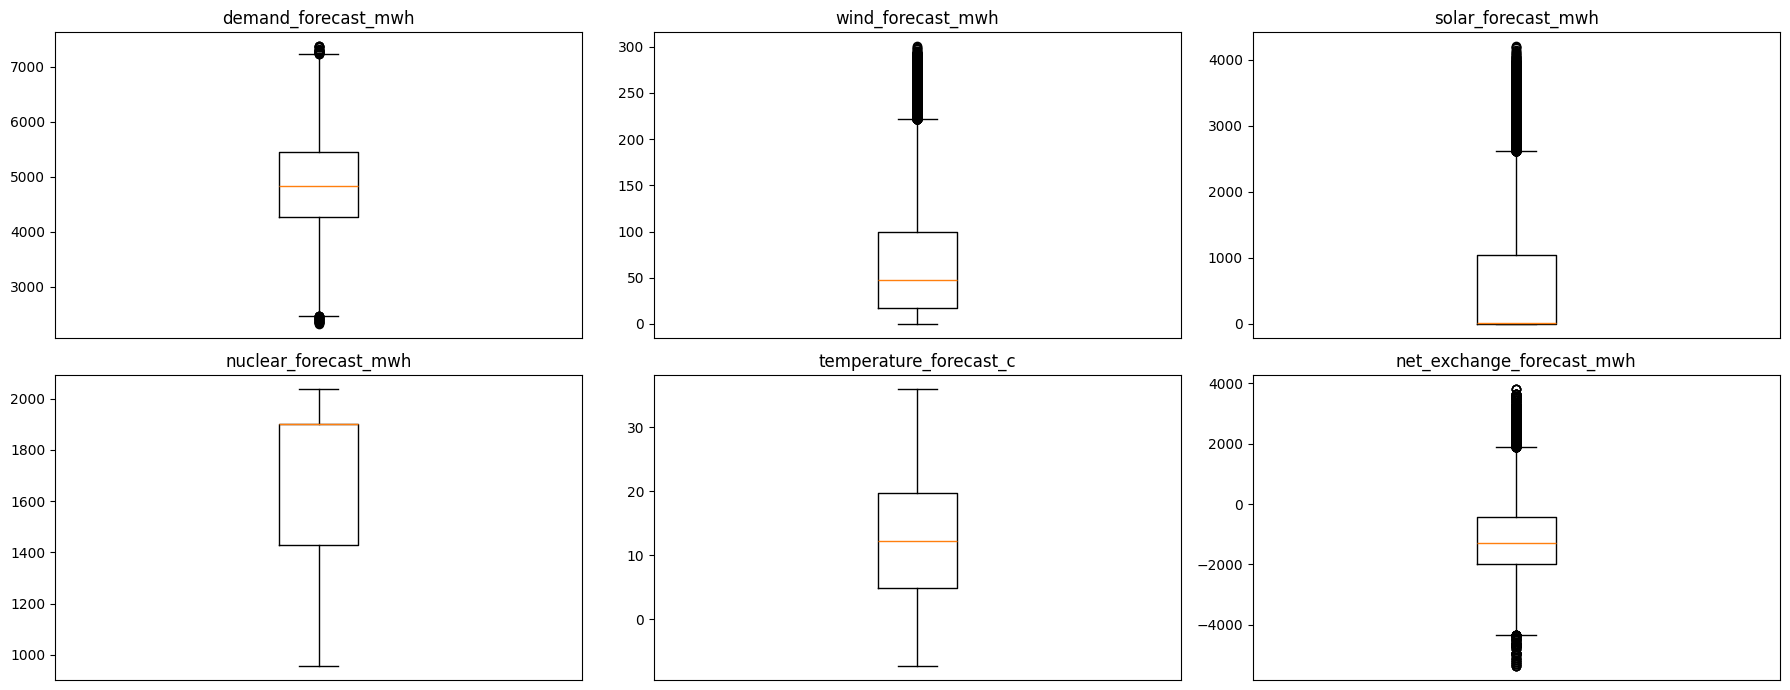

In [13]:
numeric_cols = df.select_dtypes(include=['number']).columns.drop('QH WAP')

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(df[col].dropna(), sym='o')
    ax.set_title(col)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [14]:
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[numeric_cols]), columns=numeric_cols)

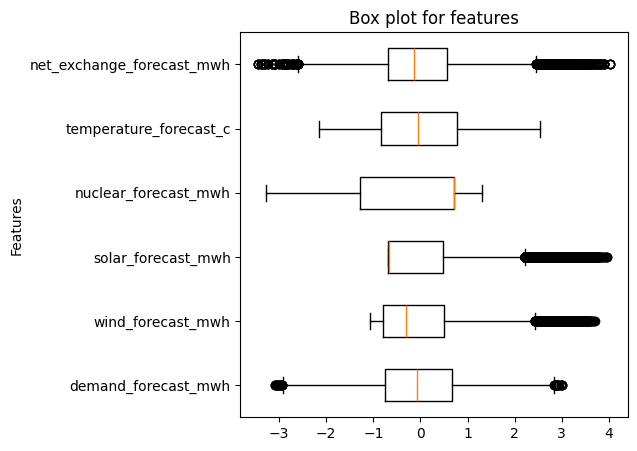

In [15]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.boxplot(x=df_scaled,
           vert=False,
           sym='o'
          )
ax.set_yticks(range(1, df_scaled.shape[1] + 1), df_scaled.columns)  # подписи признаков (работает в любой версии matplotlib)
plt.title('Box plot for features')
plt.ylabel('Features')
plt.show()

In [16]:
features = ['wind_forecast_mwh', 'solar_forecast_mwh', 'net_exchange_forecast_mwh', 'demand_forecast_mwh']

for i in features:
    p99 = df[i].quantile(0.99)

    count_above_p99 = (df[i] > p99).sum()
    share_above_p99 = (df[i] > p99).mean() * 100

    count_negative = (df[i] < 0).sum()
    share_negative = (df[i] < 0).mean() * 100

    print(f'выбросы выше 99% для {i}:') 
    print(f' P99:, {p99:.2f}')
    print(f' Количество значений выше P99:, {count_above_p99}')
    print(f' Доля значений выше P99: {share_above_p99:.2f}%')


выбросы выше 99% для wind_forecast_mwh:
 P99:, 258.20
 Количество значений выше P99:, 1048
 Доля значений выше P99: 1.00%
выбросы выше 99% для solar_forecast_mwh:
 P99:, 3375.89
 Количество значений выше P99:, 1052
 Доля значений выше P99: 1.00%
выбросы выше 99% для net_exchange_forecast_mwh:
 P99:, 2300.00
 Количество значений выше P99:, 600
 Доля значений выше P99: 0.57%
выбросы выше 99% для demand_forecast_mwh:
 P99:, 6807.86
 Количество значений выше P99:, 1052
 Доля значений выше P99: 1.00%


### Сезонность

In [17]:
df['hour'] = df['timestamp'].dt.hour

df['day_of_week'] = df['timestamp'].dt.dayofweek

df['week_of_year'] = df['timestamp'].dt.isocalendar().week

df['month'] = df['timestamp'].dt.month

df['year'] = df['timestamp'].dt.year

In [18]:
def plot_time_patterns(df, feature):

    fig, axes = plt.subplots(2, 2, figsize=(18, 10))

    days_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

    months_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

    hourly_avg = df.groupby(df['hour'])[feature].median()

    sns.lineplot(x=hourly_avg.index, y=hourly_avg.values, marker='o', ax=axes[0, 0])

    axes[0, 0].set_title('Динамика по часам')
    axes[0, 0].set_xlabel('Час')
    axes[0, 0].set_xticks(range(24))
    axes[0, 0].grid(True, alpha=0.5)

    daily_avg = df.groupby(df['day_of_week'])[feature].median()

    sns.lineplot(x=daily_avg.index, y=daily_avg.values, marker='o', ax=axes[0, 1])

    axes[0, 1].set_title('Динамика по дням недели')
    axes[0, 1].set_xlabel('День недели')
    axes[0, 1].set_xticks(range(7))
    axes[0, 1].set_xticklabels(days_labels)
    axes[0, 1].grid(True, alpha=0.5)

    weekly_avg = df.groupby(df['week_of_year'])[feature].median()

    sns.lineplot(x=weekly_avg.index, y=weekly_avg.values, marker='o', ax=axes[1, 0])

    axes[1, 0].set_title('Сезонность по неделям года')
    axes[1, 0].set_xlabel('Неделя года')
    axes[1, 0].set_xticks(range(1, 54, 4))
    axes[1, 0].grid(True, alpha=0.5)

    monthly_avg = df.groupby(df['month'])[feature].median()

    sns.lineplot(x=monthly_avg.index, y=monthly_avg.values,marker='o', ax=axes[1, 1])

    axes[1, 1].set_title('Сезонность по месяцам')
    axes[1, 1].set_xlabel('Месяц')
    axes[1, 1].set_xticks(range(1, 13))
    axes[1, 1].set_xticklabels(months_labels)
    axes[1, 1].grid(True, alpha=0.5)

    fig.suptitle(f'Временные паттерны: {feature}', fontsize=15)

    plt.tight_layout()
    plt.show()

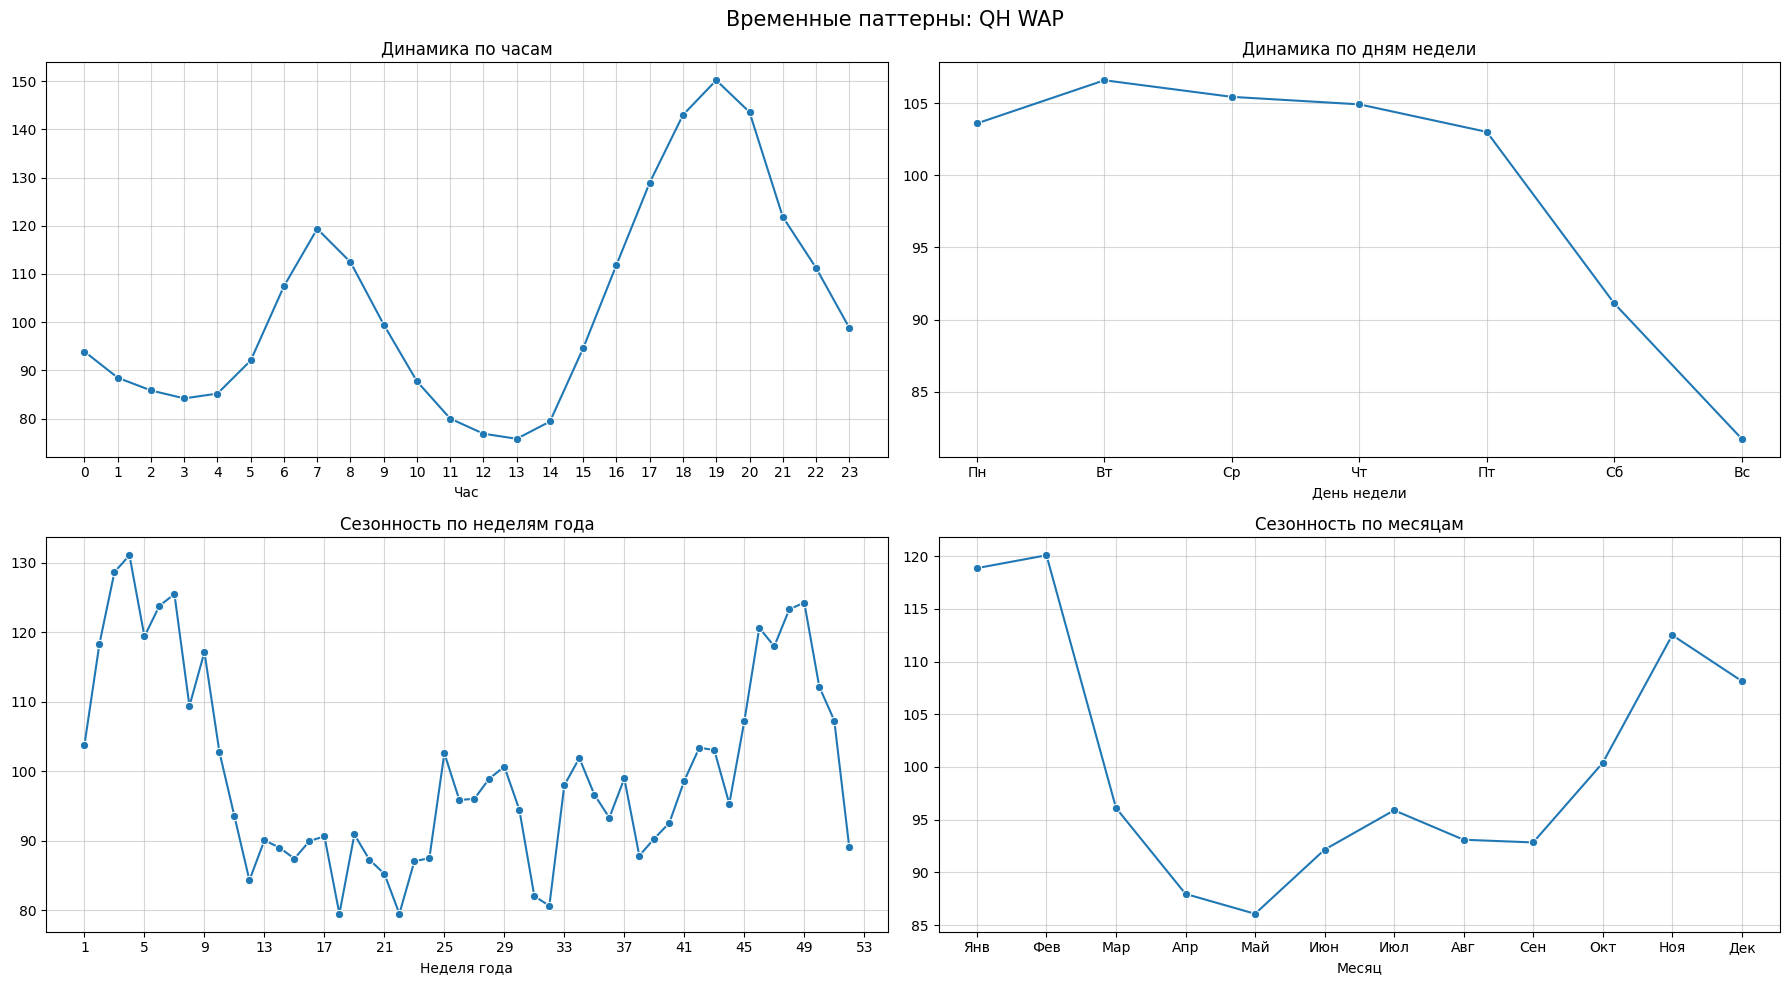

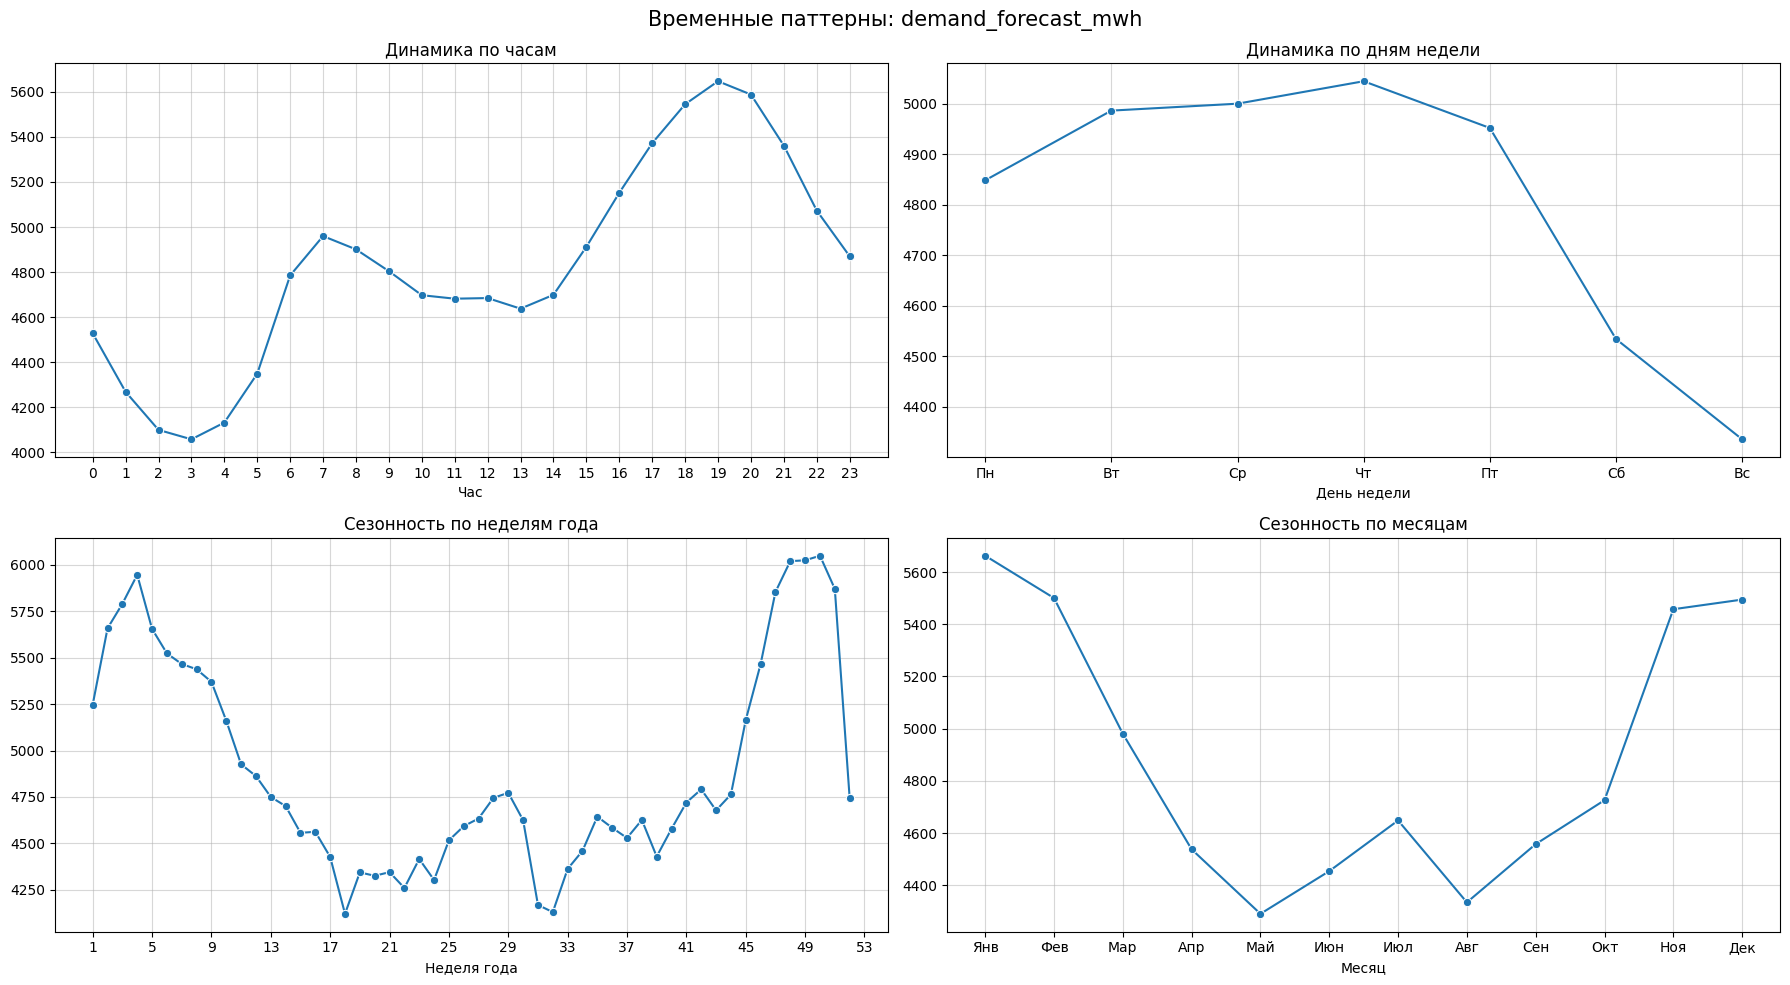

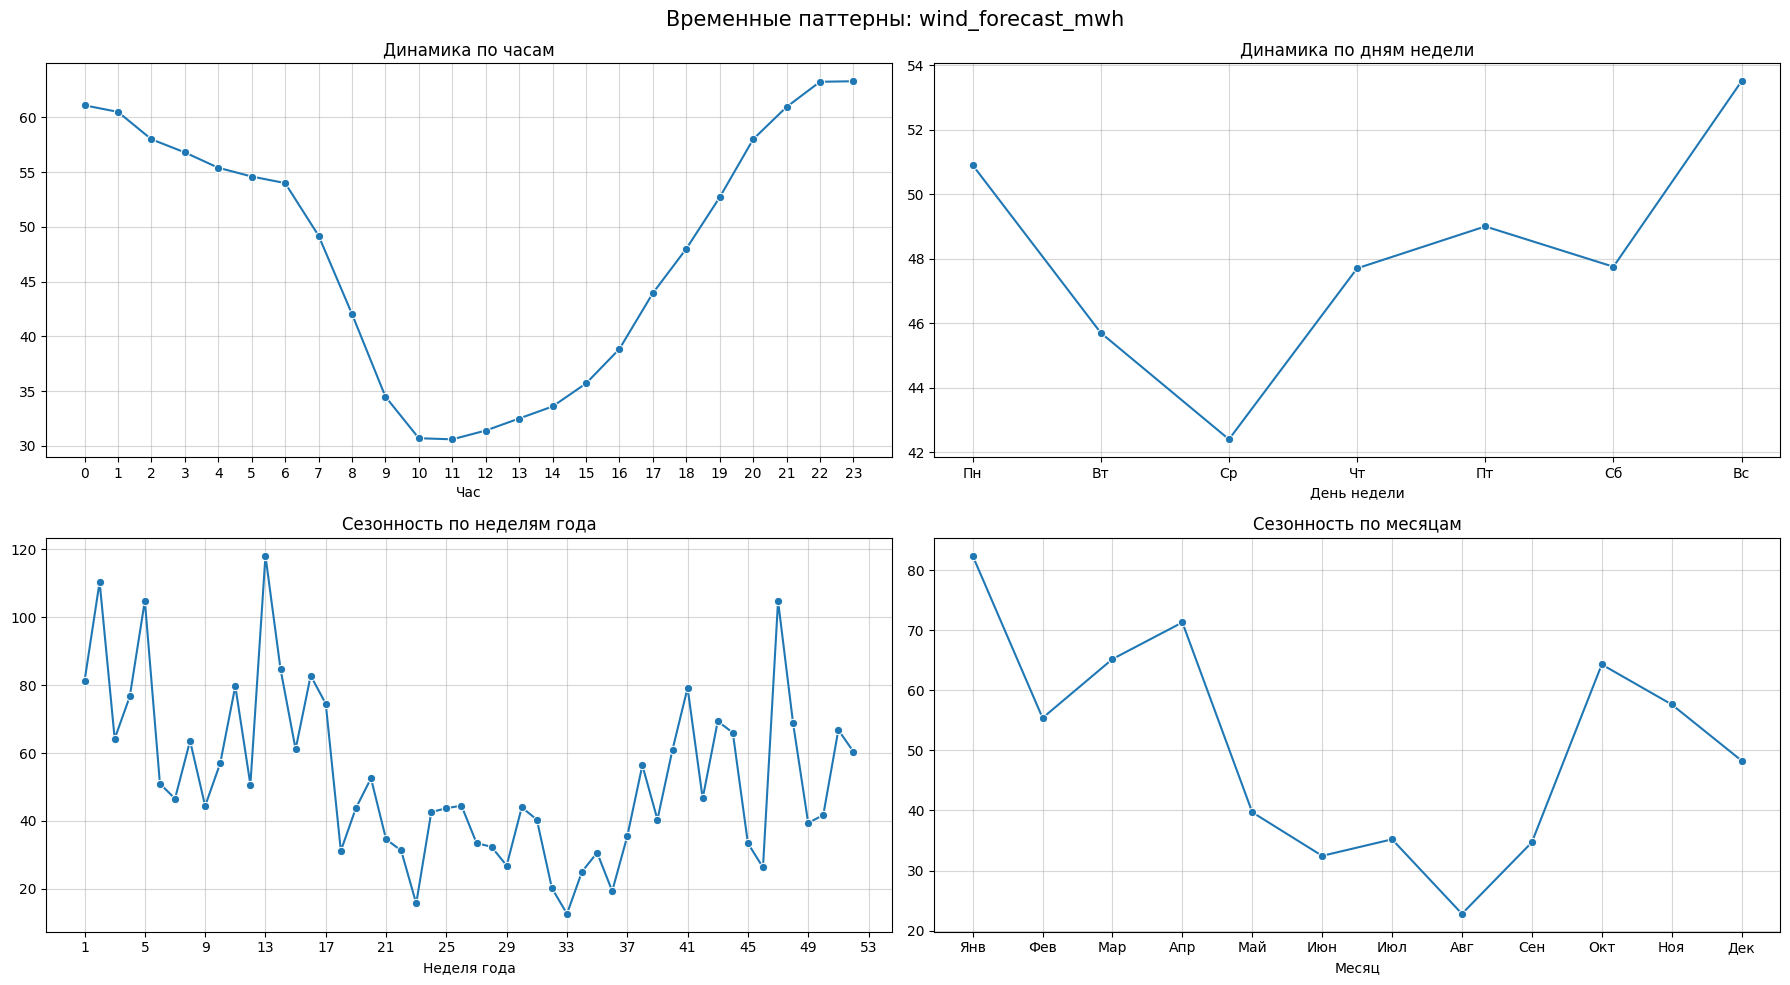

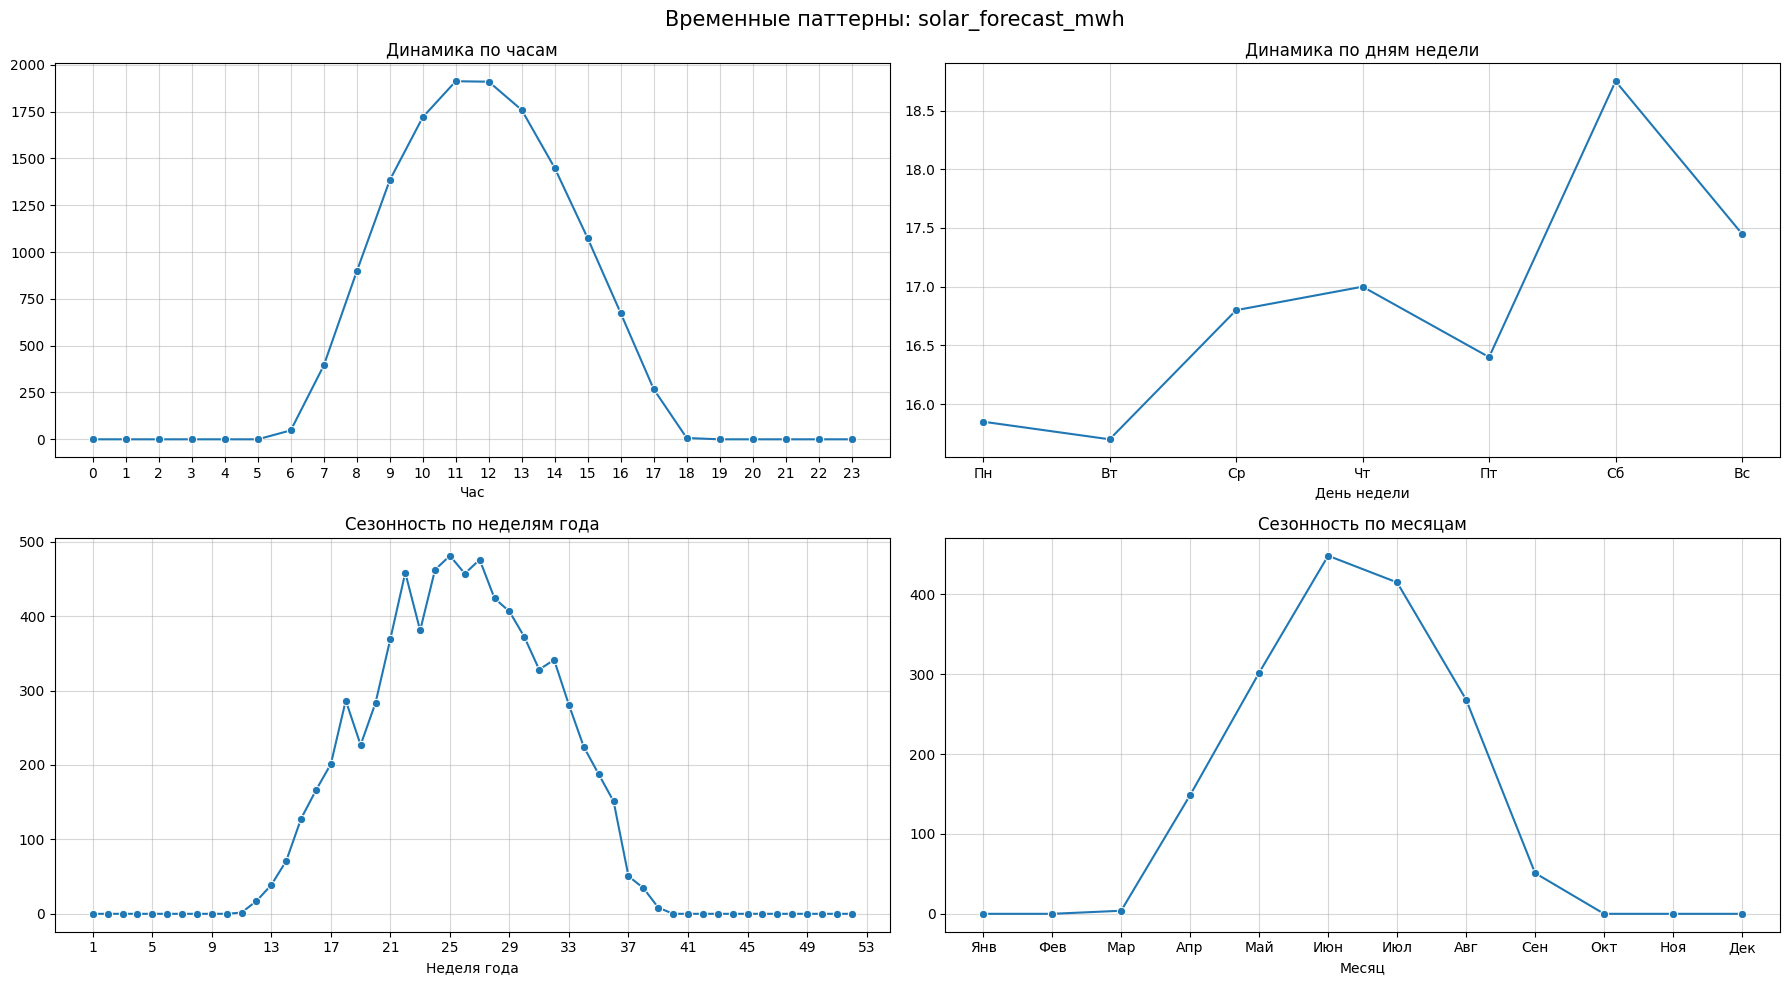

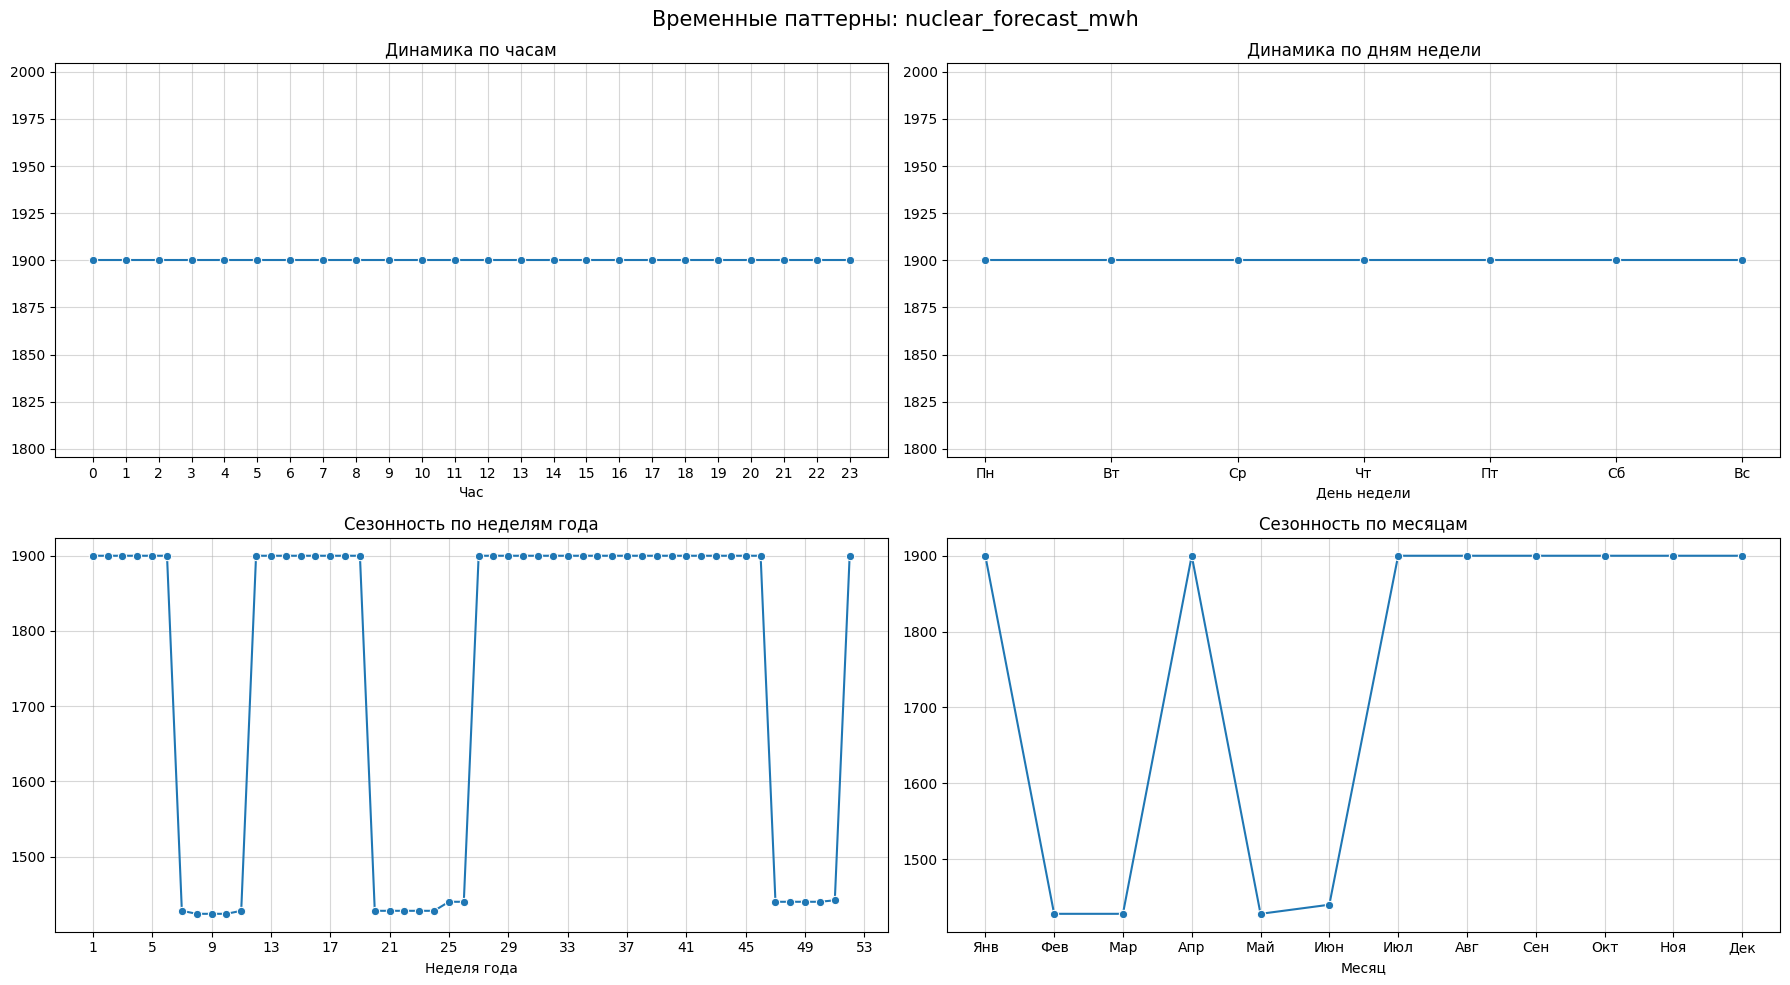

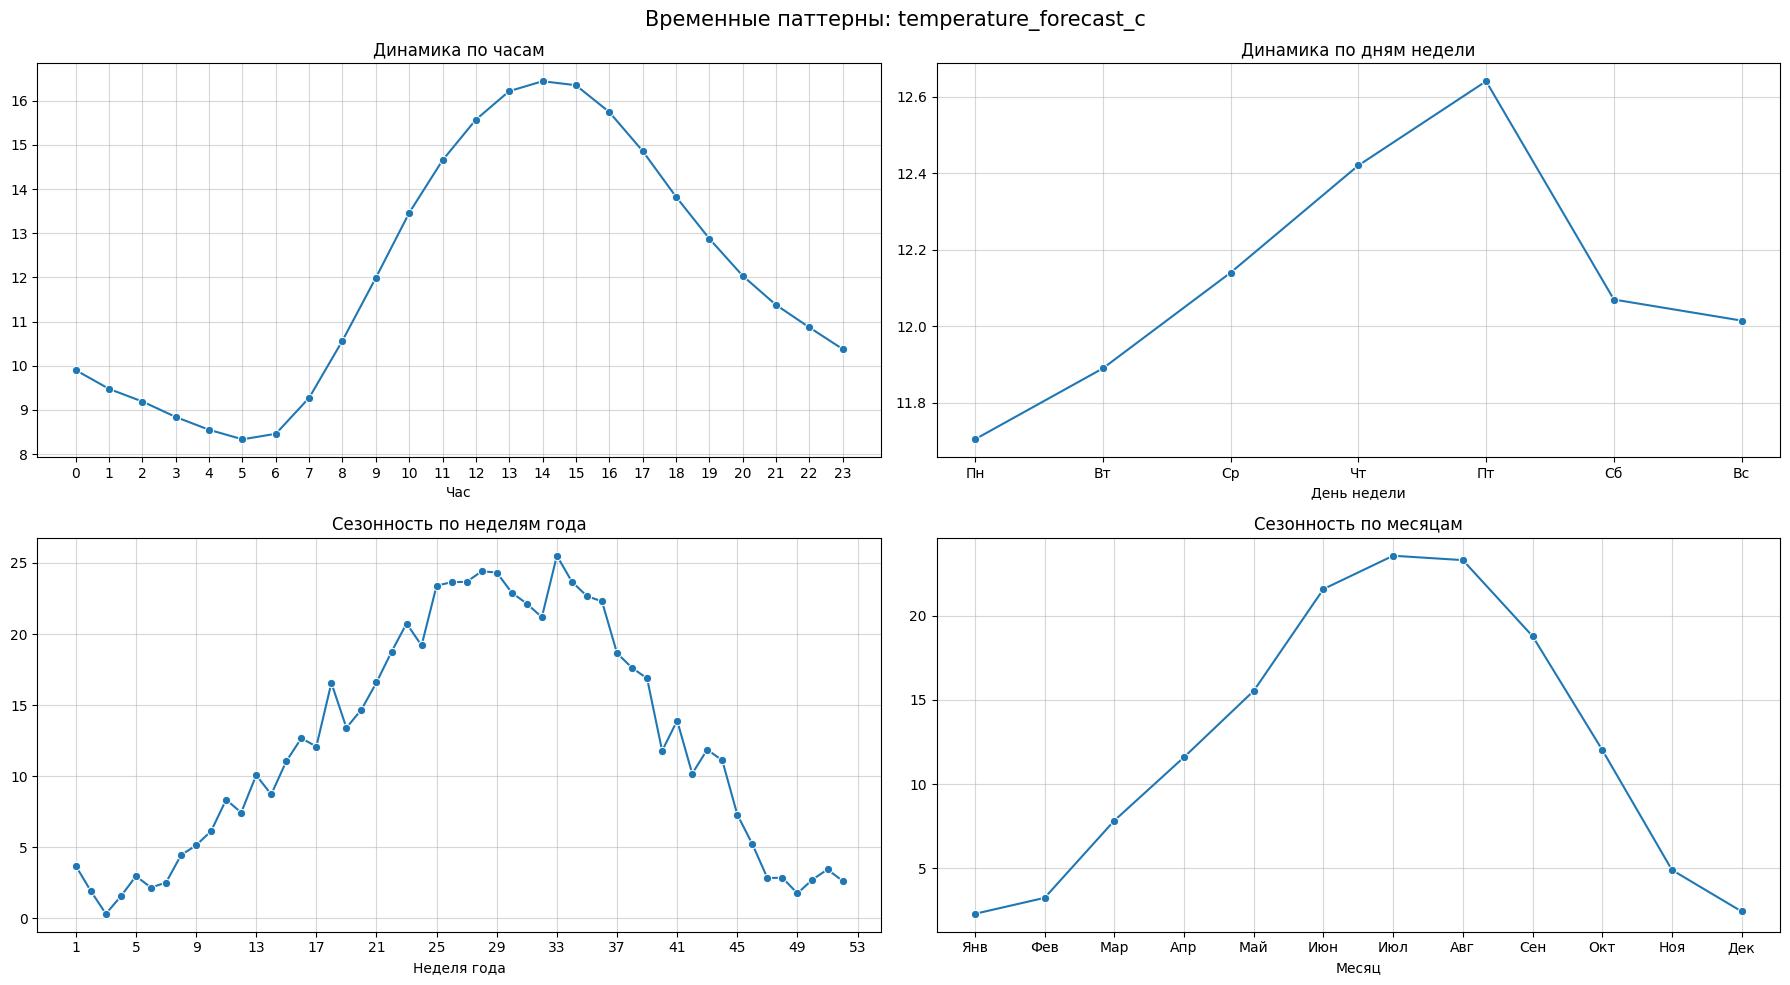

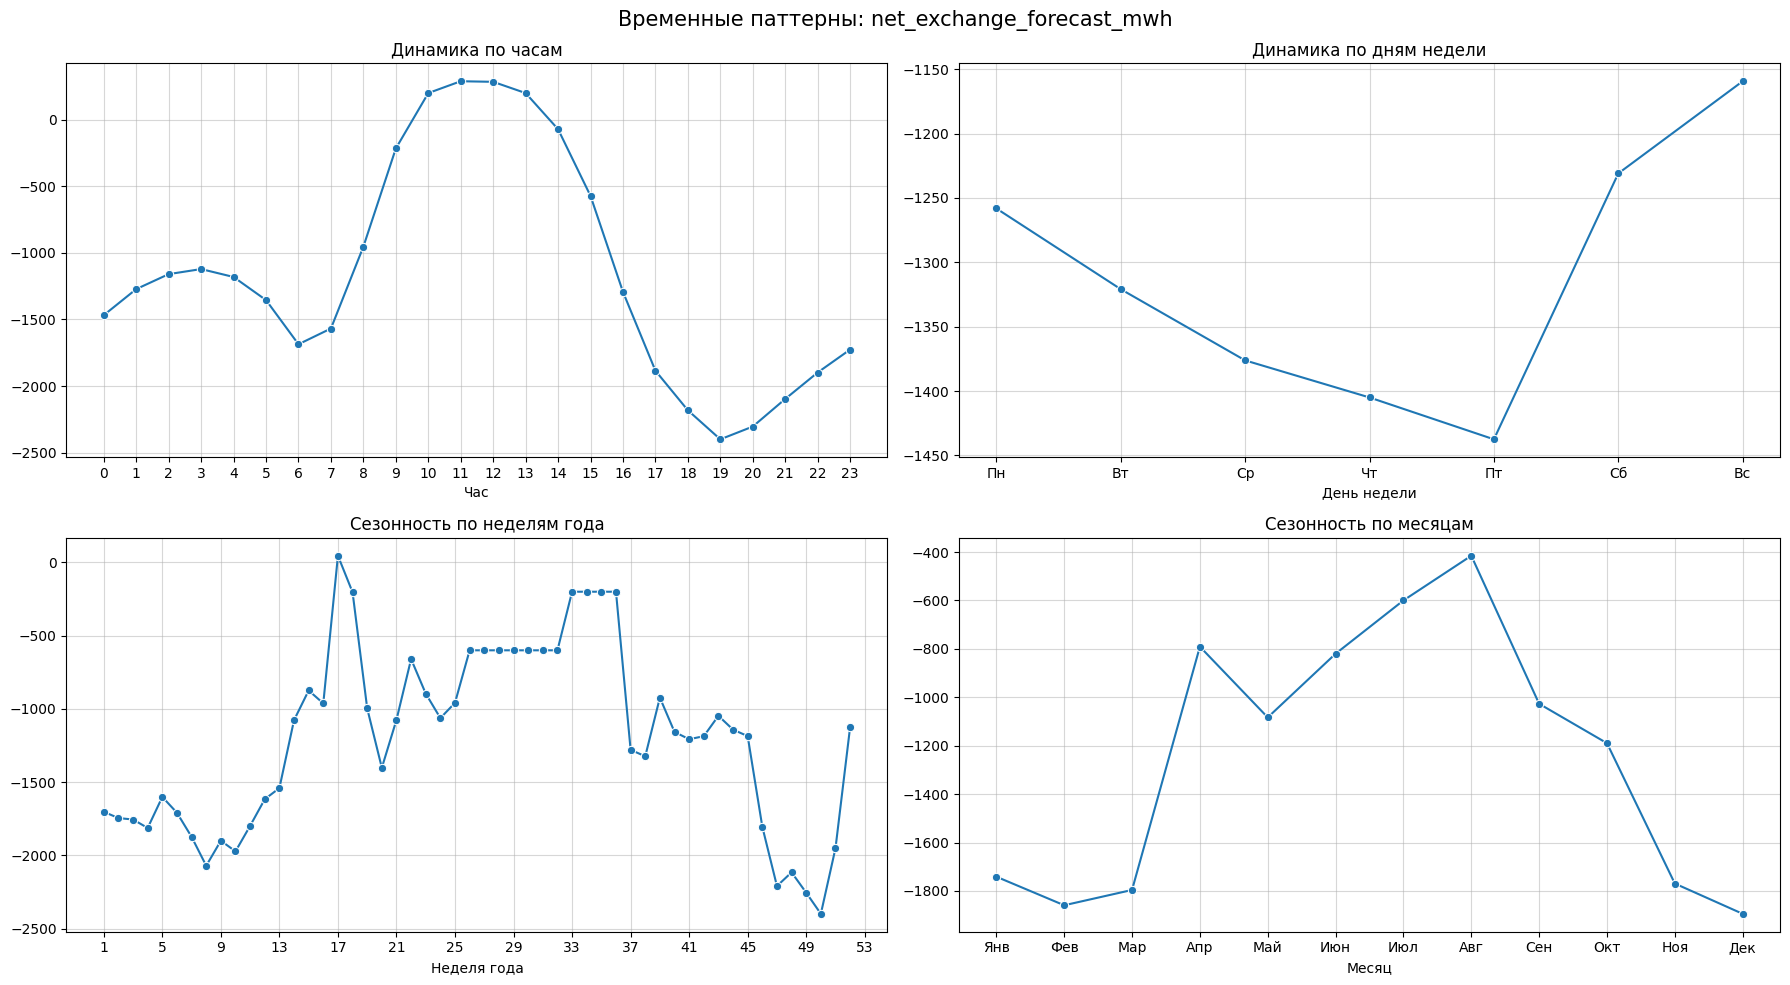

In [19]:
features = df.select_dtypes(include=['number']).columns.drop(
    ['hour', 'day_of_week', 'month', 'week_of_year', 'year'])

for feature in features:
    plot_time_patterns(df, feature)

In [20]:
def plot_time_patterns_years(df, feature):

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    days_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

    months_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

    palette = 'tab10'

    #df = df[df['year'] != 2022] - если вернуть UTC, то надо раскомментить
    
    hourly = df.groupby(['year', df['hour']])[feature].median().reset_index()

    hourly.columns = ['year', 'hour', feature]

    sns.lineplot(data=hourly, x='hour', y=feature, hue='year', marker='o', ax=axes[0, 0], palette = palette)

    axes[0, 0].set_title('Динамика по часам')
    axes[0, 0].set_xlabel('Час')
    axes[0, 0].set_xticks(range(24))
    axes[0, 0].grid(True, alpha=0.5)

    daily = df.groupby(['year', df['day_of_week']])[feature].median().reset_index()

    daily.columns = ['year', 'day', feature]

    sns.lineplot(data=daily, x='day', y=feature, hue='year', marker='o', ax=axes[0, 1], palette = palette)

    axes[0, 1].set_title('Динамика по дням недели')
    axes[0, 1].set_xlabel('День недели')
    axes[0, 1].set_xticks(range(7))
    axes[0, 1].set_xticklabels(days_labels)
    axes[0, 1].grid(True, alpha=0.5)

    weekly = df.groupby(['year', df['week_of_year']])[feature].median().reset_index()

    weekly.columns = ['year', 'week', feature]

    sns.lineplot(data=weekly, x='week', y=feature, hue='year', ax=axes[1, 0], palette = palette)

    axes[1, 0].set_title('Динамика по неделям года')
    axes[1, 0].set_xlabel('Неделя года')
    axes[1, 0].grid(True, alpha=0.5)

    monthly = df.groupby(['year', df['month']])[feature].median().reset_index()

    monthly.columns = ['year', 'month', feature]

    sns.lineplot(data=monthly, x='month', y=feature, hue='year', marker='o', ax=axes[1, 1], palette = palette)

    axes[1, 1].set_title('Динамика по месяцам')
    axes[1, 1].set_xticks(range(1, 13))
    axes[1, 1].set_xticklabels(months_labels)
    axes[1, 1].grid(True, alpha=0.5)

    fig.suptitle(f'Временные паттерны: {feature}', fontsize=15)

    plt.tight_layout()
    plt.show()

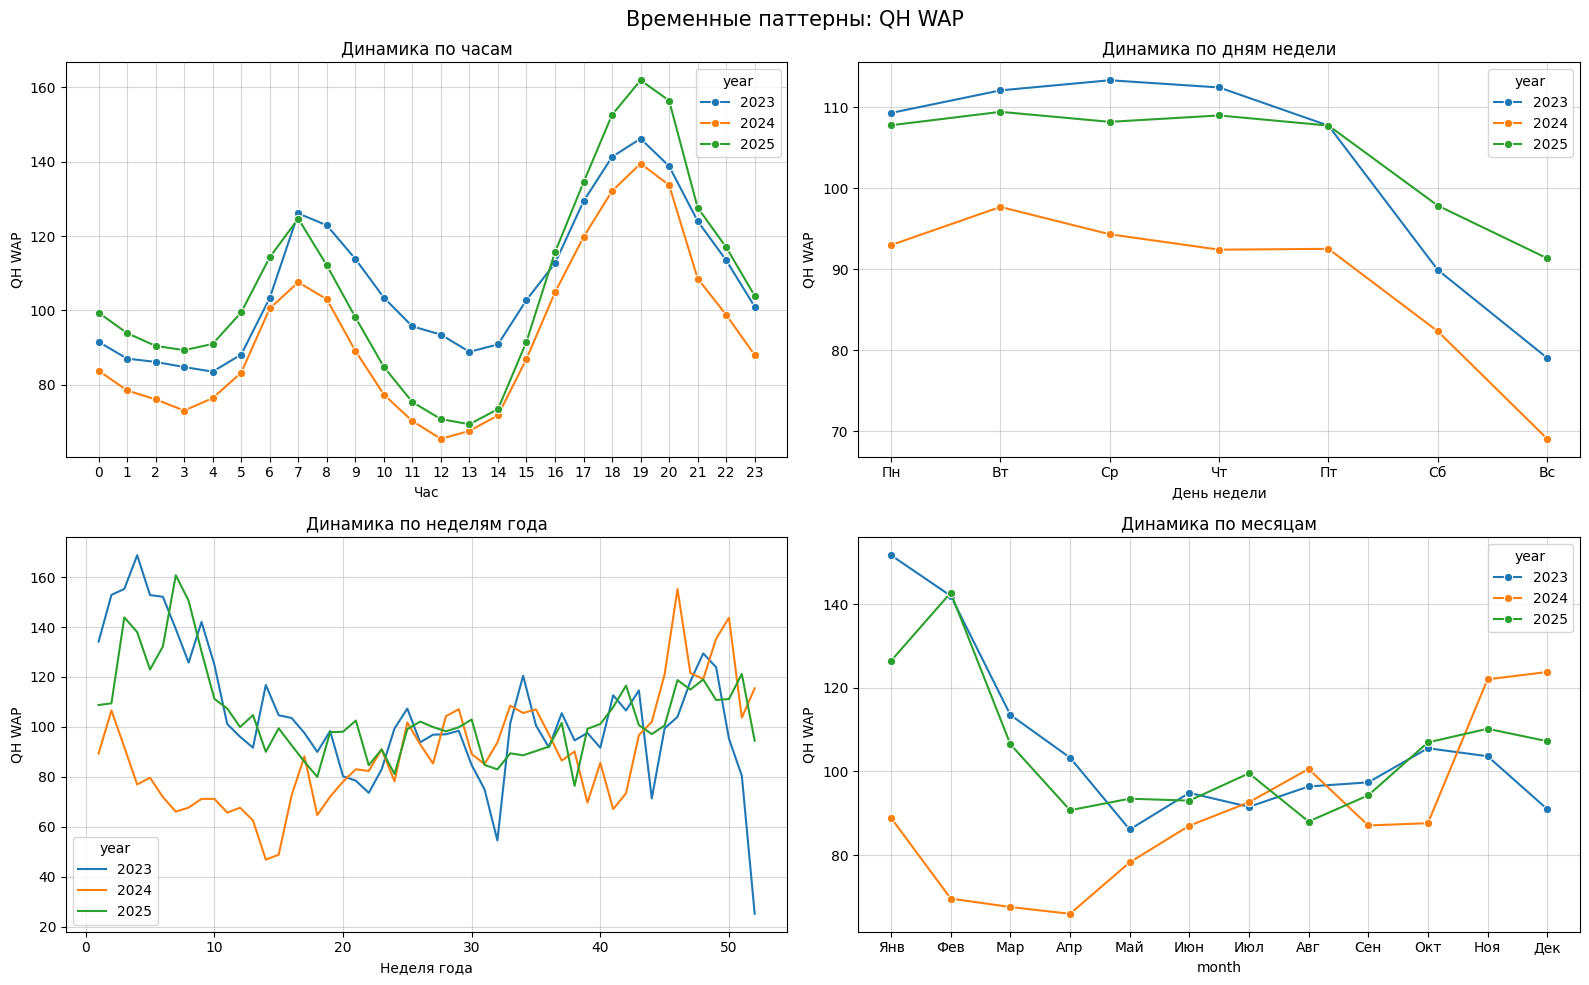

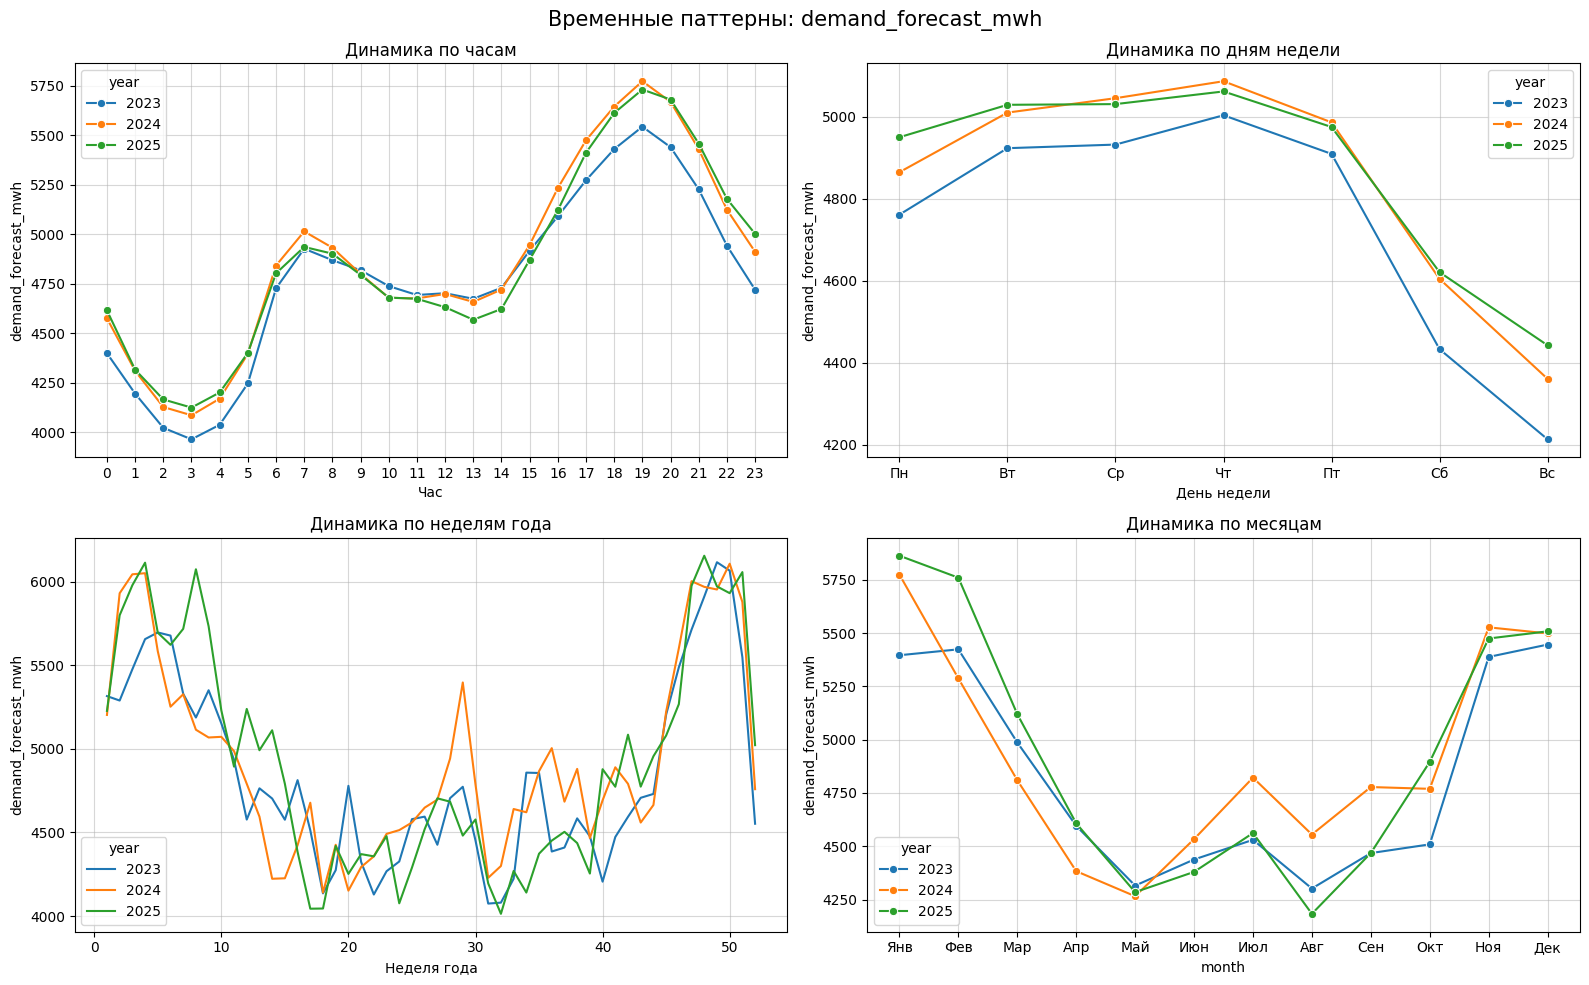

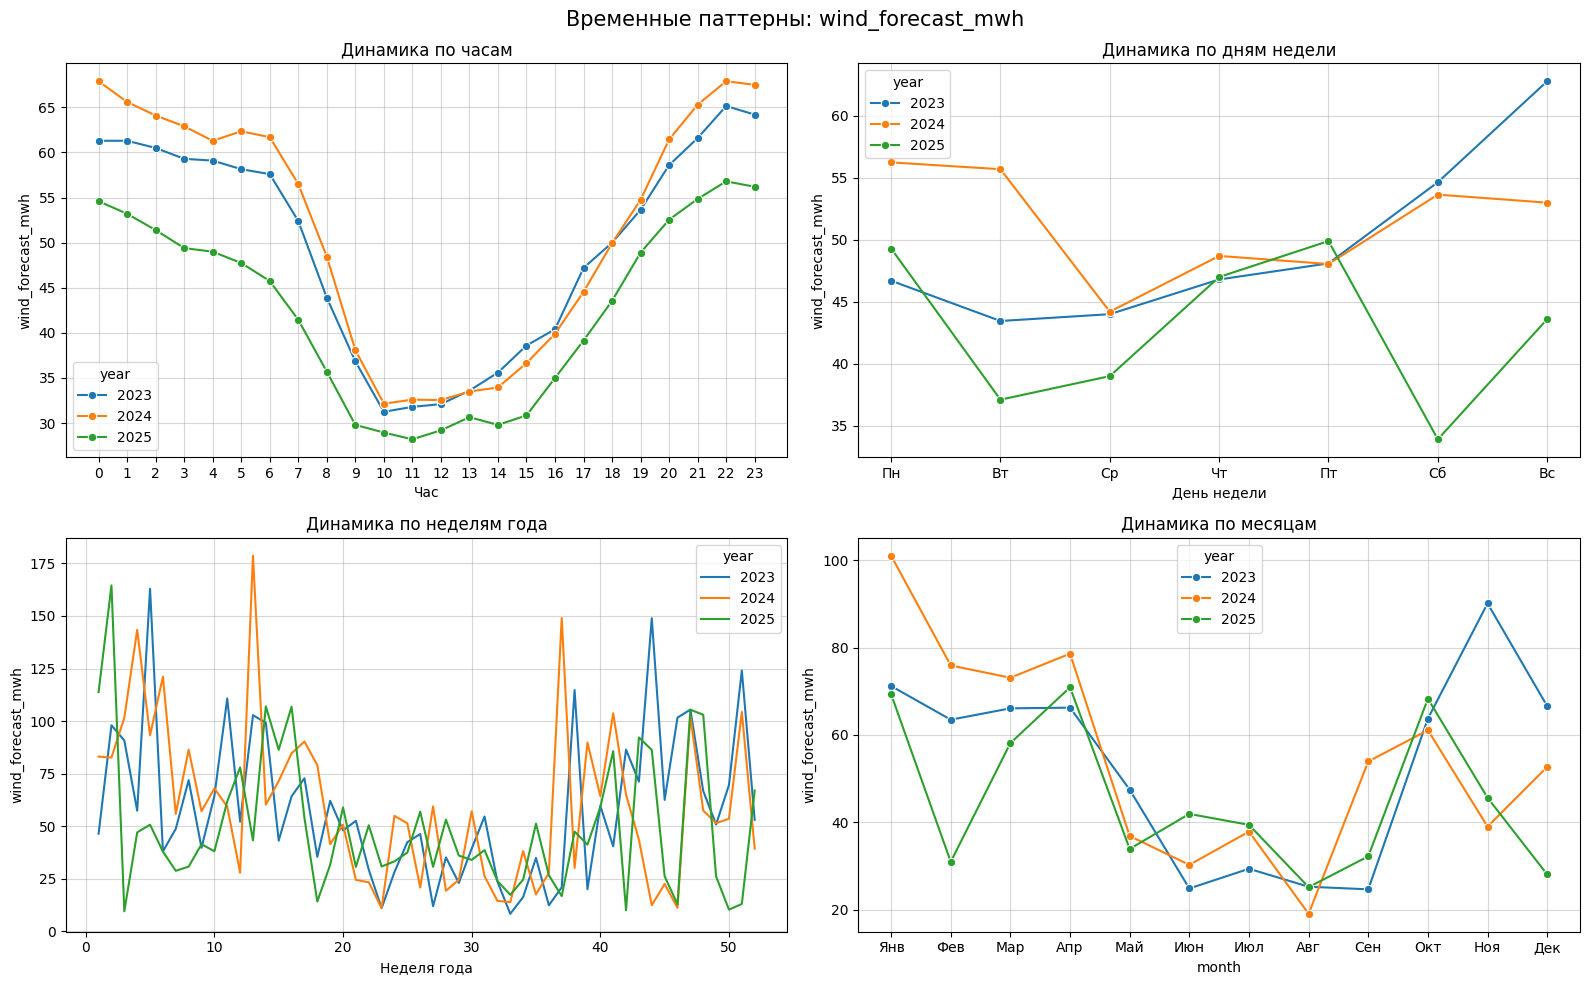

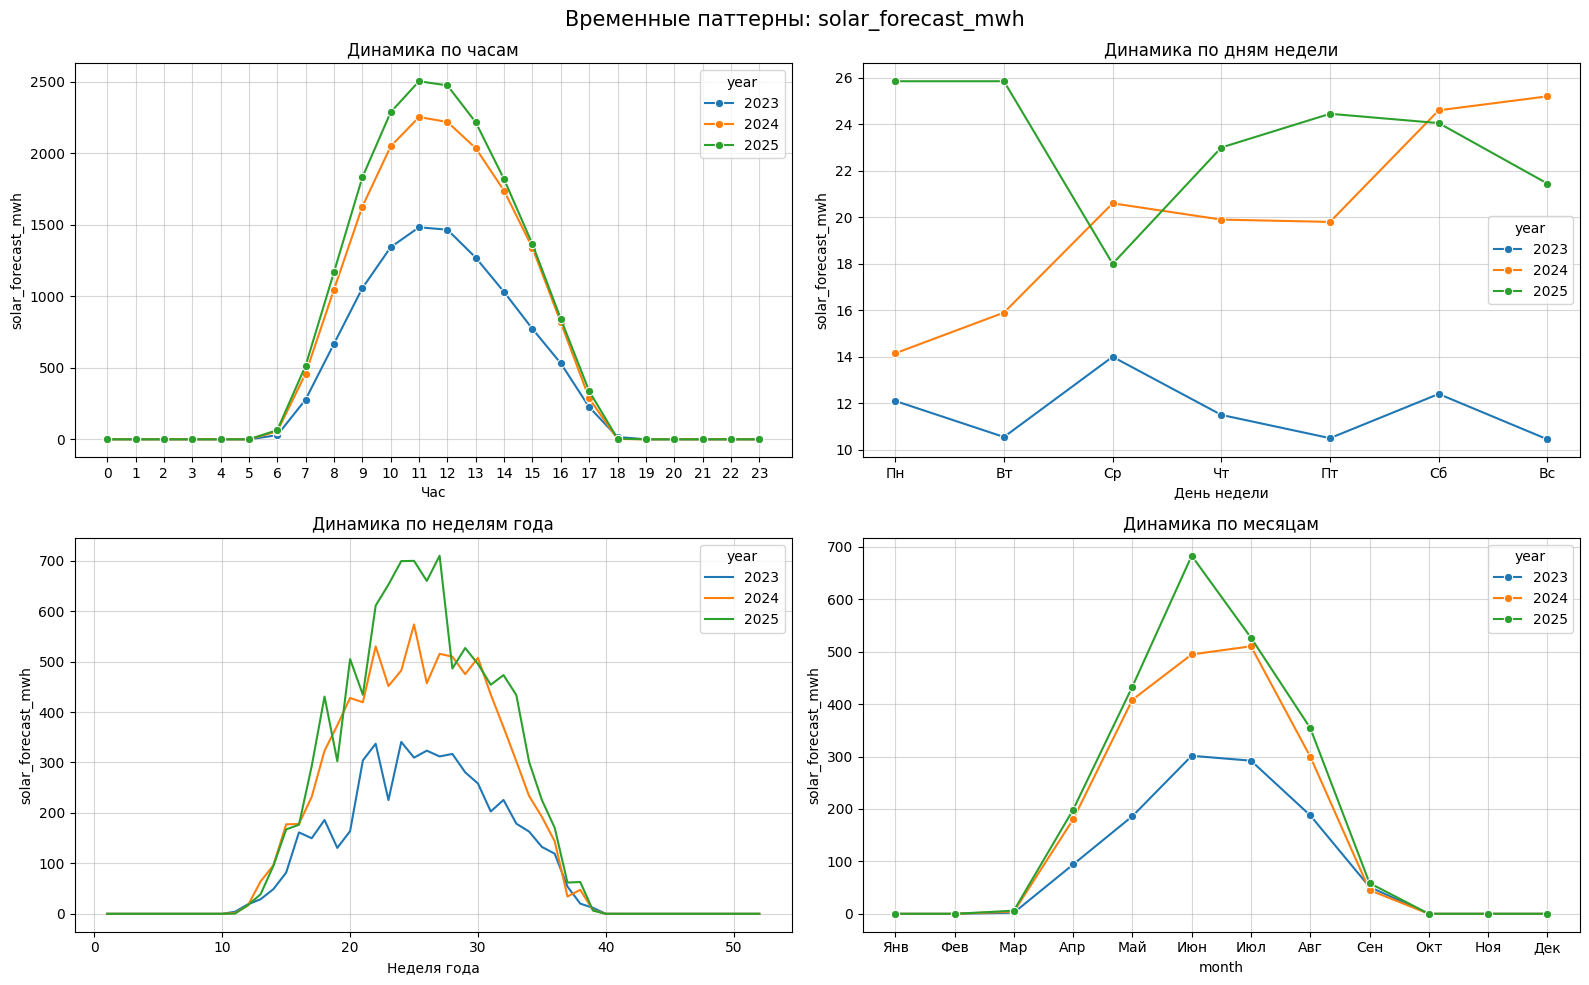

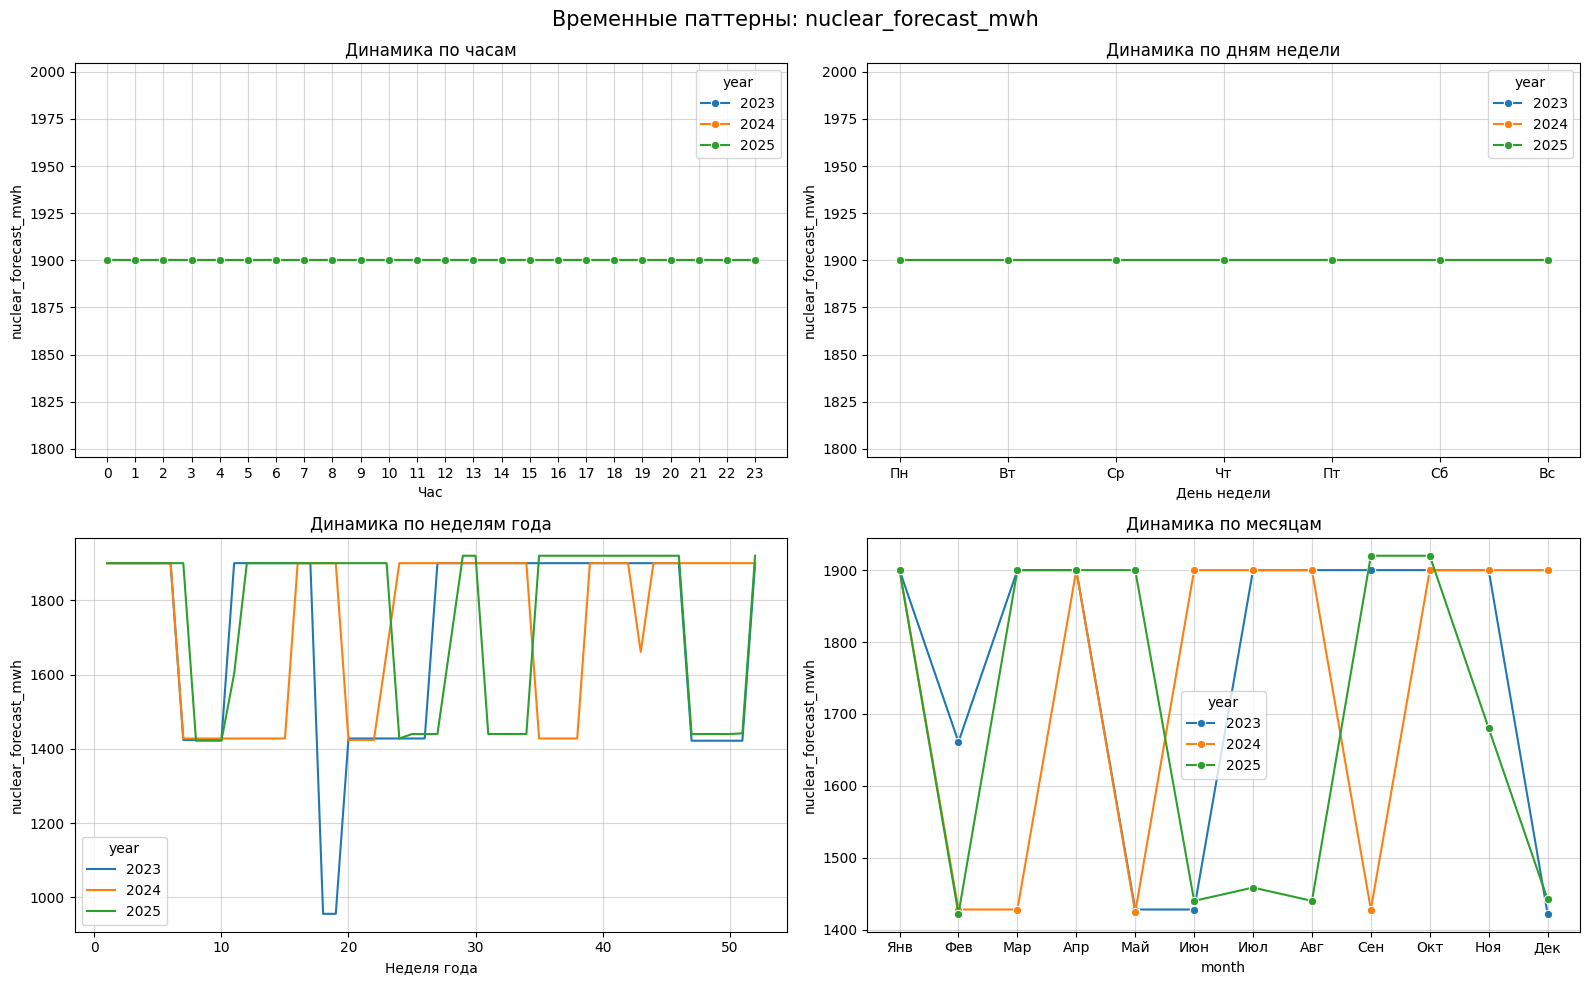

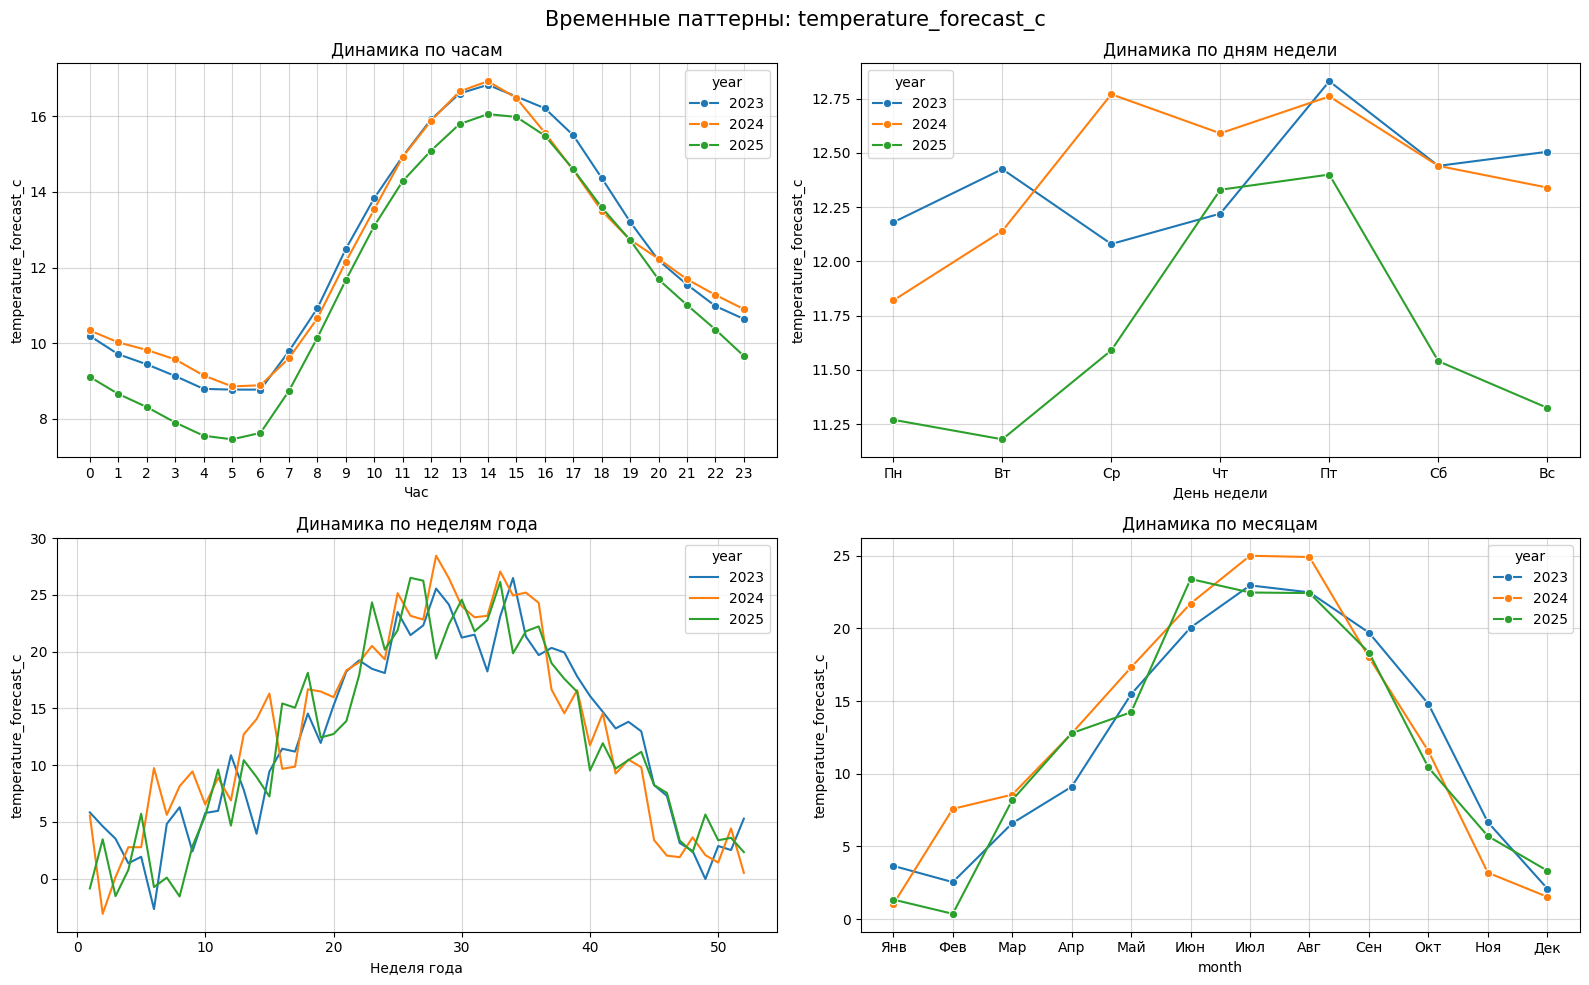

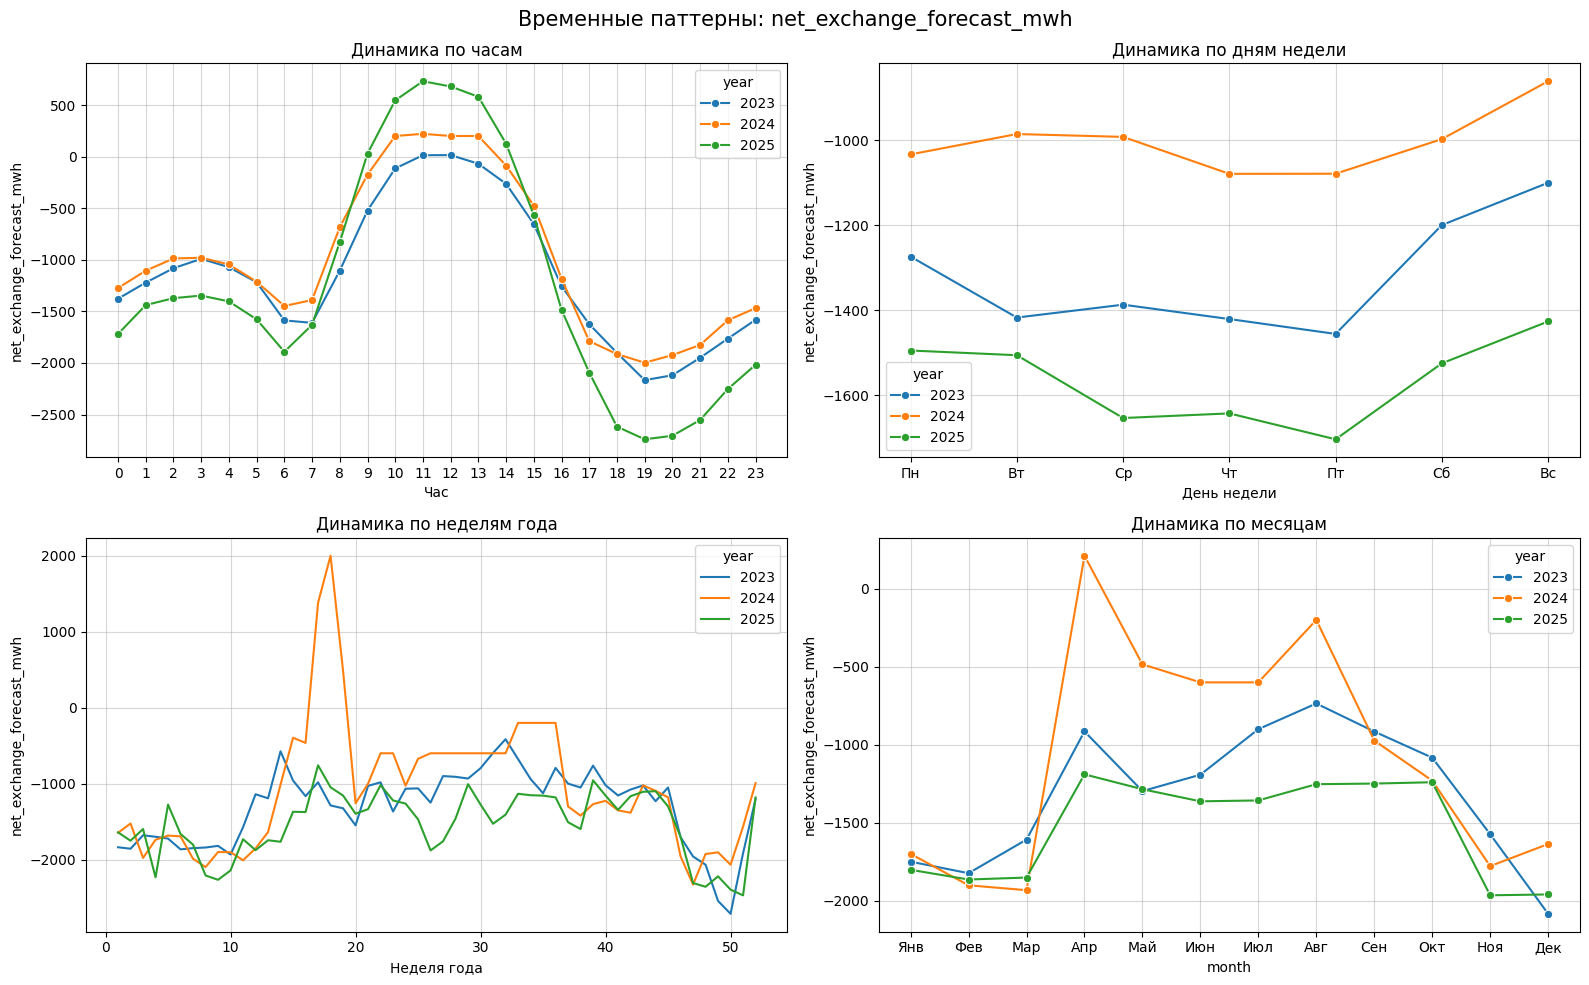

In [21]:
for feature in features:
    plot_time_patterns_years(df, feature)

### Матрицы корреляций

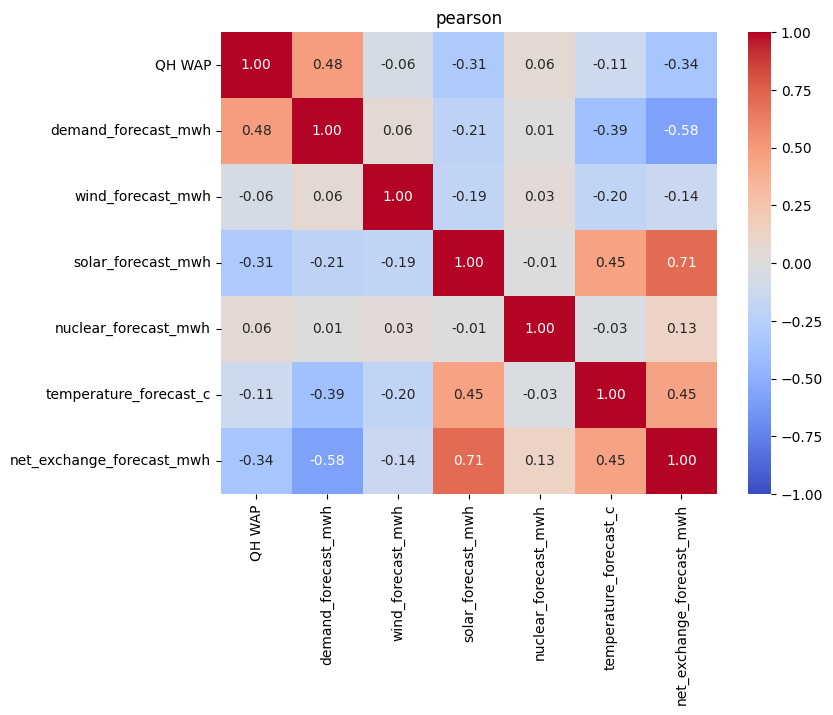

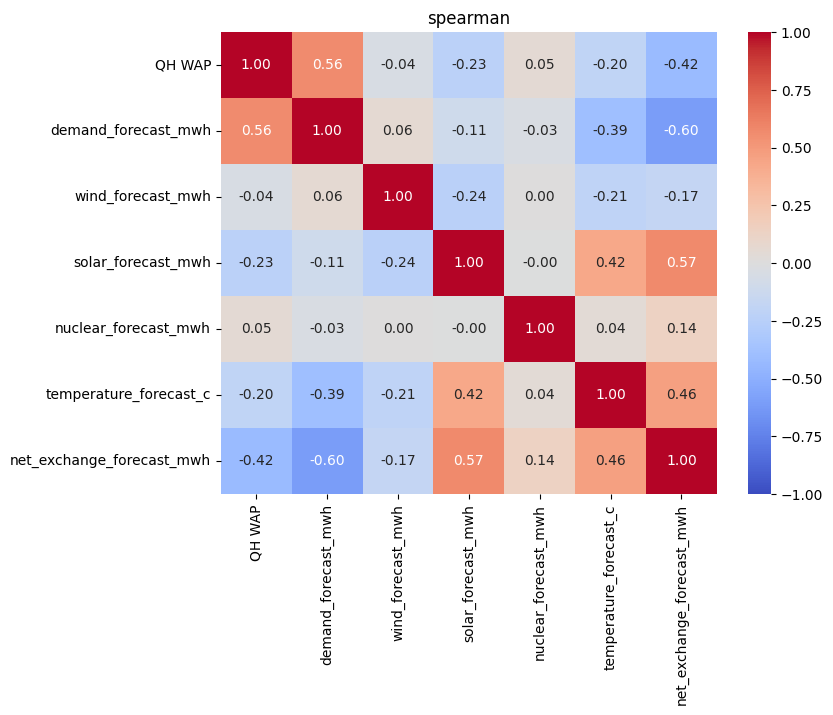

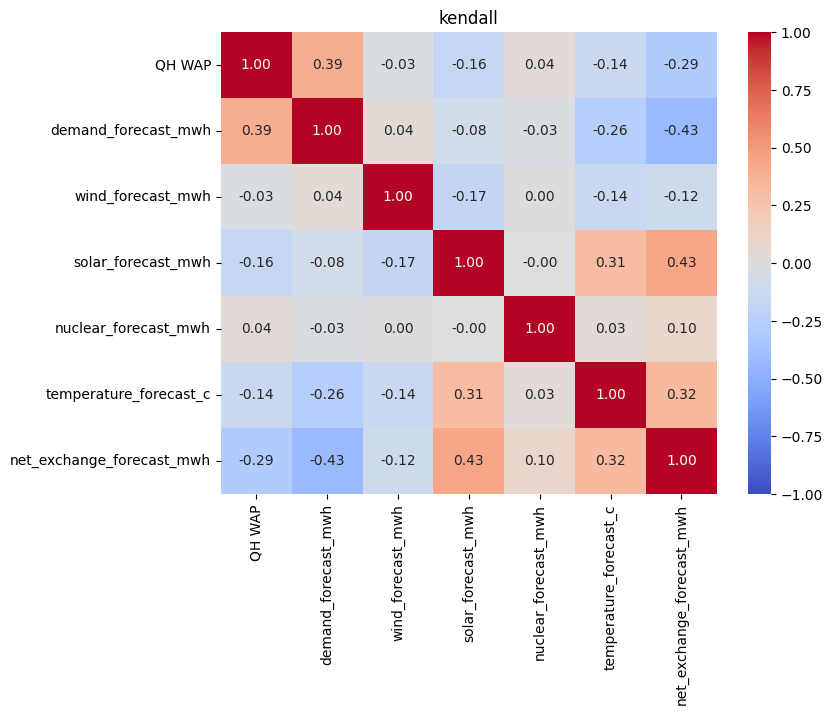

In [22]:
exclude_cols = ['timestamp', 'hour', 'day_of_week', 'month', 'week_of_year', 'year']

corr_types = ['pearson', 'spearman', 'kendall']

for i in corr_types:
    corr_matrix = df.drop(columns=exclude_cols).corr(method=i, numeric_only=True)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        corr_matrix,
        annot = True,
        cmap = 'coolwarm',
        fmt = '.2f',
        vmin = -1,
        vmax = 1
    )

    plt.title(f'{i}')
    plt.show()

### Корреляции QH WAP с признаками с лагом на сутки до недели

In [23]:
features = [
    col for col in df.select_dtypes(include='number').columns
    if col not in exclude_cols
]

results = []

for feature in features:
    for day in range(1, 8):
        lagged_feature = df[feature].shift(day * 96)

        corr = df['QH WAP'].corr(lagged_feature)

        results.append({
            'feature': feature,
            'lag_days': day,
            'correlation': corr
        })

corr_results = pd.DataFrame(results)

corr_results['abs_correlation'] = corr_results['correlation'].abs()

corr_results = corr_results.sort_values('abs_correlation', ascending=False).reset_index(drop=True)

corr_results

,feature,lag_days,correlation,abs_correlation
0,QH WAP,1,0.670075,0.670075
1,QH WAP,2,0.550202,0.550202
2,QH WAP,7,0.543673,0.543673
3,QH WAP,6,0.513832,0.513832
4,QH WAP,3,0.510078,0.510078
5,QH WAP,5,0.488292,0.488292
6,QH WAP,4,0.484158,0.484158
7,demand_forecast_mwh,1,0.414235,0.414235
8,demand_forecast_mwh,7,0.406441,0.406441
9,demand_forecast_mwh,6,0.375348,0.375348


### Корреляции QH WAP с признаками с лагом до 3 часов

In [24]:
features = [
    col for col in df.select_dtypes(include='number').columns
    if col not in exclude_cols
]

results = []

for feature in features: 
    for int in range(1, 12):
        lagged_feature = df[feature].shift(int)

        corr = df['QH WAP'].corr(lagged_feature)

        results.append({
            'feature': feature,
            'lag_15 min_intervals': int,
            'correlation': corr
        })

corr_results = pd.DataFrame(results)

corr_results['abs_correlation'] = corr_results['correlation'].abs()

corr_results = corr_results.sort_values('abs_correlation', ascending=False).reset_index(drop=True)

corr_results

,feature,lag_15 min_intervals,correlation,abs_correlation
0,QH WAP,4,0.743661,0.743661
1,QH WAP,1,0.730275,0.730275
2,QH WAP,3,0.653653,0.653653
3,QH WAP,2,0.603577,0.603577
4,QH WAP,5,0.597240,0.597240
5,QH WAP,8,0.527974,0.527974
6,QH WAP,7,0.498385,0.498385
7,QH WAP,6,0.496780,0.496780
8,demand_forecast_mwh,1,0.483180,0.483180
9,demand_forecast_mwh,2,0.478742,0.478742


### Автокорреляция со скользящей средней

In [25]:
results = []

for period in range(3, 13):
    rolling_mean = df['QH WAP'].shift(1).rolling(window=period).mean()

    corr = df['QH WAP'].corr(rolling_mean)

    results.append({
        'period': period,
        'correlation': corr
    })

rolling_corr = pd.DataFrame(results)

rolling_corr

,period,correlation
0,3,0.744413
1,4,0.785043
2,5,0.772462
3,6,0.746981
4,7,0.732134
5,8,0.727096
6,9,0.712598
7,10,0.694098
8,11,0.677351
9,12,0.663096
